# Part 2: Quantile Regression — Uncertainty Bands

This notebook builds on the preprocessing and train/test split from Notebook 1
(same X_train/X_test/y_train_log/y_test, loaded via saved .npy/.json files to
avoid re-fitting imputation/encoding and risking train/test leakage).

Goal: instead of a single point prediction, produce a valuation range
(10th/50th/90th percentile) using quantile regression, then evaluate whether
that range is trustworthy (calibration) and internally consistent (no
crossing between percentiles).

## 1. Load preprocessed data from Notebook 1

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import json
save_path = '/content/drive/MyDrive/Football_market_inf'

X_train = np.load(f'{save_path}/X_train.npy')
X_test = np.load(f'{save_path}/X_test.npy')
y_train_log = np.load(f'{save_path}/y_train_log.npy')
y_test_log = np.load(f'{save_path}/y_test_log.npy')
y_test = np.load(f'{save_path}/y_test.npy')

with open(f'{save_path}/feature_names.json', 'r') as f:
    feature_names = json.load(f)

print("Loaded:", X_train.shape, X_test.shape, len(feature_names))

Mounted at /content/drive
Loaded: (1401, 27) (351, 27) 27


## 2. Train quantile regression models

Three separate GradientBoostingRegressor models, one per quantile
(alpha = 0.1, 0.5, 0.9), trained on the same log1p-transformed target
used in Notebook 1. Predictions are converted back to euros with expm1 —
this is valid because quantiles are preserved under monotonic
transformations (unlike the mean).

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
import numpy as np

gbr_10 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    loss='quantile',
    alpha=0.1,
    random_state=42
)
gbr_10.fit(X_train, y_train_log)
pred_10_log = gbr_10.predict(X_test)
pred_10 = np.expm1(pred_10_log)

gbr_50 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    loss='quantile',
    alpha=0.5,
    random_state=42
)
gbr_50.fit(X_train, y_train_log)
pred_50_log = gbr_50.predict(X_test)
pred_50 = np.expm1(pred_50_log)

gbr_90 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    loss='quantile',
    alpha=0.9,
    random_state=42
)
gbr_90.fit(X_train, y_train_log)
pred_90_log = gbr_90.predict(X_test)
pred_90 = np.expm1(pred_90_log)

In [ ]:
print(pred_10[:5])
print(pred_50[:5])
print(pred_90[:5])

[18063164.52584798 16076572.15843284 11414463.30524687 10764612.64342425
   660758.55574951]
[28008710.78044919 39753776.90339835 32970732.821845   18592758.81412555
  1859050.44635268]
[45453308.54393953 51539230.16904576 44308120.12629889 31762688.0748148
 10122357.9313667 ]


## 3. Quantile crossing check

Quantile crossing occurs when pred_50 >= pred_90 (or pred_10 >= pred_50) —
a logical inconsistency that can happen because the three models are fit
independently. Checking for it here before trusting the bands.

In [ ]:
violations_10_50 = (pred_10 >= pred_50).sum()
violations_50_90 = (pred_50 >= pred_90).sum()

print("Violations where pred_10 >= pred_50:", violations_10_50)
print("Violations where pred_50 >= pred_90:", violations_50_90)

Violations where pred_10 >= pred_50: 0
Violations where pred_50 >= pred_90: 5


In [ ]:
crossing_mask = pred_50 >= pred_90
print("Number of violations:", crossing_mask.sum())
print("pred_50 values:", pred_50[crossing_mask])
print("pred_90 values:", pred_90[crossing_mask])

Number of violations: 5
pred_50 values: [7.71261389e+07 2.14978562e+07 2.43387830e+07 1.43155319e+08
 6.23989718e+07]
pred_90 values: [5.15524475e+07 2.12480291e+07 2.42585339e+07 1.13265790e+08
 6.15325510e+07]


In [ ]:
violating_indices = np.where(crossing_mask)[0]

for i in violating_indices:
    print("Player index:", i, "pred_50: €", pred_50[i], "pred_90: €", pred_90[i], "gap: €", pred_90[i] - pred_50[i])

Player index: 5 pred_50: € 77126138.91459812 pred_90: € 51552447.533503115 gap: € -25573691.381095007
Player index: 252 pred_50: € 21497856.19556999 pred_90: € 21248029.13335467 gap: € -249827.06221531704
Player index: 285 pred_50: € 24338783.041589353 pred_90: € 24258533.92378953 gap: € -80249.11779982224
Player index: 326 pred_50: € 143155319.36345893 pred_90: € 113265790.18610977 gap: € -29889529.177349165
Player index: 340 pred_50: € 62398971.775930636 pred_90: € 61532551.03500874 gap: € -866420.7409218922


In [ ]:
age_col = feature_names.index('Yaş')
asr_col = feature_names.index('ASR')
print(age_col, asr_col)

19 20


In [ ]:
for i in violating_indices:
    print("Player", i,
          "| actual: €", y_test[i],
          "| age:", X_test[i,age_col],
          "| ASR:", X_test[i, asr_col],
          "| pred_50: €", pred_50[i],
          "| pred_90: €", pred_90[i])

Player 5 | actual: € 55000000 | age: 31.0 | ASR: 7.58 | pred_50: € 77126138.91459812 | pred_90: € 51552447.533503115
Player 252 | actual: € 12000000 | age: 29.0 | ASR: 6.93 | pred_50: € 21497856.19556999 | pred_90: € 21248029.13335467
Player 285 | actual: € 25000000 | age: 29.0 | ASR: 6.91 | pred_50: € 24338783.041589353 | pred_90: € 24258533.92378953
Player 326 | actual: € 100000000 | age: 29.0 | ASR: 7.39 | pred_50: € 143155319.36345893 | pred_90: € 113265790.18610977
Player 340 | actual: € 70000000 | age: 29.0 | ASR: 7.53 | pred_50: € 62398971.775930636 | pred_90: € 61532551.03500874


### Follow-up: is the age-29 clustering real, or a small-sample coincidence?

4 of 5 crossing violations occurred at age 29. Checking the average
(pred_90 - pred_50) band width for the full group of age-29 players in
the test set (not just the violators) to see if this holds at scale.

In [ ]:
age_mask_29 = X_test[:, age_col]==29
print(age_mask_29.sum())

19


In [ ]:
gap = pred_90 - pred_50
avg_gap_29 = gap[age_mask_29].mean()
avg_gap_other = gap[~age_mask_29].mean()

print("Average gap for age 29:", avg_gap_29)
print("Average gap for other ages:", avg_gap_other)

Average gap for age 29: 6922184.723876137
Average gap for other ages: 15179132.324055936


## 4. Calibration check

For each quantile model, the fraction of actual test values falling below
the predicted line should roughly match the target quantile (e.g. ~10% of
actuals below the pred_10 line). This checks whether the bands are honest,
not just whether RMSE looks reasonable.

In [ ]:
pct_below_10 = (y_test < pred_10).mean() * 100
print(pct_below_10)

pct_below_50 = (y_test < pred_50).mean() * 100
print(pct_below_50)

pct_below_90 = (y_test < pred_90).mean() * 100
print(pct_below_90)

13.390313390313391
47.008547008547005
83.47578347578347


In [ ]:
low_cutoff = np.percentile(y_test, 33)
high_cutoff = np.percentile(y_test, 66)

print("Low cutoff: €", low_cutoff)
print("High cutoff: €", high_cutoff)

Low cutoff: € 13000000.0
High cutoff: € 25000000.0


In [ ]:
low_mask = low_cutoff >= y_test
mid_mask = (y_test > low_cutoff) & (y_test < high_cutoff)
high_mask = high_cutoff <= y_test

print(low_mask.sum(), mid_mask.sum(), high_mask.sum())
print(low_mask.sum() + mid_mask.sum() + high_mask.sum())

120 91 140
351


In [ ]:
np.random.seed(42)

low_indices = np.where(low_mask)[0]
mid_indices = np.where(mid_mask)[0]
high_indices = np.where(high_mask)[0]

sample_low = np.random.choice(low_indices, size=12, replace=False)
sample_mid = np.random.choice(mid_indices, size=12, replace=False)
sample_high = np.random.choice(high_indices, size=12, replace=False)

sample_indices = np.concatenate([sample_low, sample_mid, sample_high])
print(len(sample_indices))

36


In [ ]:
sample_actual = y_test[sample_indices]
sample_pred_10 = pred_10[sample_indices]
sample_pred_50 = pred_50[sample_indices]
sample_pred_90 = pred_90[sample_indices]

In [ ]:
order = np.argsort(sample_actual)

sample_actual_sorted = sample_actual[order]
sample_pred_10_sorted = sample_pred_10[order]
sample_pred_50_sorted = sample_pred_50[order]
sample_pred_90_sorted = sample_pred_90[order]

print(sample_actual_sorted)

[ 3000000  4000000  4500000  5000000  5000000  5000000  5000000  8000000
 10000000 12000000 12000000 13000000 15000000 16000000 17000000 18000000
 18000000 18000000 20000000 20000000 22000000 22000000 22000000 22000000
 25000000 25000000 28000000 35000000 35000000 35000000 40000000 44000000
 45000000 55000000 55000000 75000000]


## 5. Visualizing the bands

Sampling 36 test players across low/mid/high value terciles (12 each,
using the test set's own 33rd/66th percentiles as cutoffs) for a readable
plot. Sorted by actual value so the band's behavior across the value range
is easy to see.

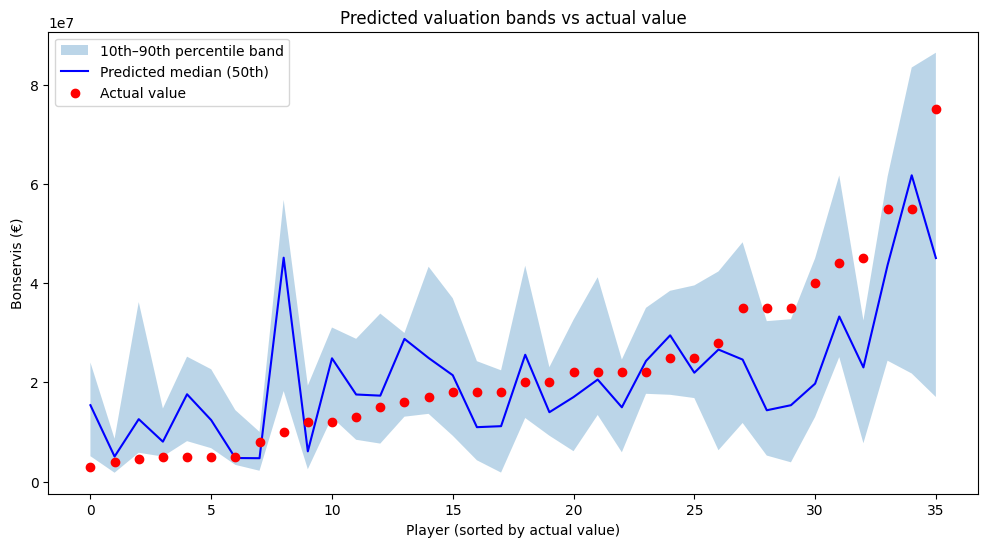

In [ ]:
import matplotlib.pyplot as plt

x = np.arange(len(sample_actual_sorted))

plt.figure(figsize=(12, 6))

plt.fill_between(x, sample_pred_10_sorted, sample_pred_90_sorted, alpha=0.3, label='10th–90th percentile band')
plt.plot(x, sample_pred_50_sorted, color='blue', label='Predicted median (50th)')
plt.scatter(x, sample_actual_sorted, color='red', label='Actual value', zorder=5)

plt.xlabel('Player (sorted by actual value)')
plt.ylabel('Bonservis (€)')
plt.title('Predicted valuation bands vs actual value')
plt.legend()
plt.show()

### Follow-up: does the median underprediction hold on the full test set?

The plot suggested the median underpredicts high-value players. Verifying
this on the real top 10% of the full test set (not just the 36-player
plotting sample) before treating it as a real finding.

In [ ]:
print(sample_actual_sorted[-10:])
print(sample_pred_50_sorted[-10:])

[28000000 35000000 35000000 35000000 40000000 44000000 45000000 55000000
 55000000 75000000]
[26604446.21297678 24582646.74739497 14366654.22998976 15387500.13135538
 19733364.72388011 33264379.48026488 23004538.17064302 43613458.0985341
 61733655.24898191 45050653.72823004]


In [ ]:
last10_actual = sample_actual_sorted[-10:]
last10_pred50 = sample_pred_50_sorted[-10:]

underpredicted = (last10_actual > last10_pred50).sum()
print(underpredicted, "out of 10")

9 out of 10


In [ ]:
top10_cutoff = np.percentile(y_test, 90)
top10_cutoff_mask = y_test > top10_cutoff
print(top10_cutoff_mask.sum())

35


In [ ]:
underpredicted_top10 = (y_test[top10_cutoff_mask]> pred_50[top10_cutoff_mask]).sum()
print(underpredicted_top10, "out of",top10_cutoff_mask.sum())

30 out of 35


## 6. Summary and limitations

The quantile bands are useful as a rough valuation range, but they are
least reliable for the highest-value players.

- **Calibration.** 13.4% of actual values fell below the 10th percentile line
  (target 10%), 47.0% below the 50th (target 50%), and 83.5% below the 90th
  (target 90%). The upper line is drawn too low: 16.5% of players ended up
  above it instead of the expected 10%.
- **Median bias for top players.** For the 35 players in the top 10% of
  actual value, the median prediction was below the actual value in 30 cases
  (85.7%). This held on the full test set, not just the plotting sample.
- **Quantile crossing.** In 5 of 351 test players (1.4%), pred_50 was greater
  than or equal to pred_90. Four of the five were age 29. For the 19 age-29
  players in the test set, the average band width (pred_90 − pred_50) was
  about €6.9M, versus €15.2M for other ages. This was not controlled for
  player value, and it is based on a small group, so it is an observation
  to investigate, not a proven rule.
- **Same pattern as Part 1.** The Random Forest also showed errors growing
  for high-value players. Across both models, the weakness appears at the top
  of the value range.
- **Not checked.** Calibration was measured on the whole test set, not
  separately by value tier, so we don't know how well the bands work for
  low- and mid-value players. This would be a natural next check.
- **Likely cause.** The feature set contains only on-pitch statistics. Elite
  valuations probably depend on things it doesn't capture, such as
  reputation or media profile, contract situation, scarcity, and tactical
  importance.
- **Method.** One train/test split, default GBM hyperparameters, and no
  fix applied for